# Supplementary figure: performance by cancer type, stage and ichorCNA tumor fraction

Two rows (top: BRCA/CRC versus healthy; bottom: pan-cancer versus healthy), no_deep cohort only.

| columns | content | source (`data/no_deep/`) |
|---|---|---|
| 1 | AUROC of the data-driven model by stage and by cancer type, participant-level bootstrap 95% intervals | `figS10_by_stage_and_type.csv` (written by `figS10.ipynb`) |
| 2 | sensitivity at the 95%-specificity threshold by stage and cancer type, detected/total, exact binomial 95% intervals | same file |
| 3 | paired differences in the held-out posterior, data-driven minus ATAC-seq and minus RNA-seq, by ichorCNA tumor-fraction group | `figS13_predictions.csv`, `fig4_baseline_scalars.csv` |
| 4 (pan-cancer row) | share called cancer at the 95%-specificity threshold of each outer fold's training samples, by tumor-fraction group, four methods | same files |

The BRCA/CRC version of column 4 is Figure 3b: this notebook writes its counts to `data/no_deep/fig3b_calls.csv`, which `fig3.ipynb` draws.
Output: `output/no_deep/figS_strata.png` (600 dpi) and `.pdf`. Runs from the repository root or from `src/figures`.

## Set-up and data

In [1]:
import os

# Data and output paths are relative to src/figures/; hop there if the kernel started elsewhere
if not os.path.isdir("data") and os.path.isdir(os.path.join("src", "figures", "data")):
    os.chdir(os.path.join("src", "figures"))
assert os.path.isdir("data"), "start the kernel in the repository root or in src/figures"

COHORT = "no_deep"                                   # 164 healthy donors, 203 cancers (80 BRCA/CRC)
_DATA = os.path.join("data", COHORT)
_OUT = os.path.join("output", COHORT)
_REPO = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))   # src/figures -> repository root
os.makedirs(_OUT, exist_ok=True)


def data_path(name):
    """Source data of the cohort (src/figures/data/<cohort>/)."""
    return os.path.join(_DATA, name)


def out_path(name):
    """Figure output of the cohort (src/figures/output/<cohort>/)."""
    return os.path.join(_OUT, name)


def repo_path(*parts):
    """A file outside src/figures, from the repository root."""
    return os.path.join(_REPO, *parts)


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import _figstyle as fs
fs.apply()
from matplotlib.lines import Line2D
from scipy import stats
from scipy.stats import rankdata, beta as beta_dist
from sklearn.metrics import roc_curve

# names and colors as in Figure 3
TASKS = {"brca_crc": "BRCA/CRC versus healthy", "pancan": "Pan-cancer versus healthy"}
S10_TASK = {"brca_crc": "BRCA/CRC", "pancan": "PANCAN"}          # task keys of figS10_by_stage_and_type.csv
METHODS = ["data_driven", "atac", "rna", "ichorcna"]
LAB = {"data_driven": "Data-driven", "atac": "ATAC-seq", "rna": "RNA-seq", "ichorcna": "ichorCNA"}
COLORS = {m: fs.METHOD[LAB[m]] for m in METHODS}                 # shared figure style (_figstyle)
# tumor-fraction groups of the cancers: lower bound (inclusive), upper bound (exclusive), key, tick label
BINS = [(-np.inf, 0.01, "TF < 0.01", "< 0.01"), (0.01, 0.03, "0.01 <= TF < 0.03", "0.01–0.03"),
        (0.03, np.inf, "TF >= 0.03", "≥ 0.03")]
GROUPS = ["Healthy"] + [b[2] for b in BINS]
GROUP_TICK = {"Healthy": "Healthy", **{b[2]: b[3] for b in BINS}}
STAGES = ["I", "II", "III", "IV"]


def clopper_pearson(k, n, alpha=0.05):
    """Exact binomial interval for k of n."""
    return (0.0 if k == 0 else float(beta_dist.ppf(alpha / 2, k, n - k + 1)),
            1.0 if k == n else float(beta_dist.ppf(1 - alpha / 2, k + 1, n - k)))


def auc_from_scores(pos, neg):
    r = rankdata(np.concatenate([pos, neg]))
    return (r[:len(pos)].sum() - len(pos) * (len(pos) + 1) / 2) / (len(pos) * len(neg))


def ichor_threshold(train):
    """95%-specificity threshold of the tumor fraction on a training partition
    (last ROC point with specificity >= 0.95, as in fig3.ipynb)."""
    fpr, _, thr = roc_curve(train["y_true"], train["tf"])
    return thr[np.where(1 - fpr >= 0.95)[0][-1]]


# --- columns 1 and 2: the table behind Figure S10 h-k (figS10.ipynb, section 1h) ------------------
strata_tab = pd.read_csv(data_path("figS10_by_stage_and_type.csv"))

# --- columns 3 and 4: held-out posteriors, thresholds and the rerun ichorCNA tumor fractions ------
# data-driven = figS13 arm `tuned` (k tuned in the inner loop); ATAC-seq, RNA-seq = arm `fixed`;
# ichorCNA = the tumor fraction, thresholded per outer fold on that fold's training samples.
scal = pd.read_csv(data_path("fig4_baseline_scalars.csv"))            # sample table of the cohort (both tasks)
meta = scal[["sample_id", "y_true", "disease", "stage", "ichorcna_tf"]].rename(columns={"ichorcna_tf": "tf"})
meta["stage"] = meta["stage"].astype(str).str.strip()
assert len(meta) == len(scal) == 367 and int((meta["y_true"] == 0).sum()) == 164 and int((meta["y_true"] == 1).sum()) == 203
s13 = pd.read_csv(data_path("figS13_predictions.csv"))


def load(task):
    """One row per sample of the task: held-out score, fold threshold and call of every method, and the group."""
    sel = {"data_driven": "tuned", "atac": "fixed", "rna": "fixed"}
    t = s13[s13["task"] == task]
    arms = {m: t[(t["method"] == m) & (t["arm"] == a)].set_index("sample_id") for m, a in sel.items()}
    ids = arms["data_driven"].index
    assert ids.is_unique
    df = meta.set_index("sample_id").loc[ids].reset_index()
    df["fold"] = arms["data_driven"].loc[ids, "fold"].to_numpy().astype(int)
    assert (df["y_true"].to_numpy() == arms["data_driven"].loc[ids, "y_true"].to_numpy()).all()
    for m, a in arms.items():
        assert set(a.index) == set(ids) and (a.loc[ids, "fold"].to_numpy() == df["fold"]).all(), (task, m)
        df[f"score_{m}"] = a.loc[ids, "score"].to_numpy()
        df[f"thr_{m}"] = a.loc[ids, "threshold_95spec"].to_numpy()
    thr = {f: ichor_threshold(df[df["fold"] != f]) for f in df["fold"].unique()}   # training samples of the fold
    df["score_ichorcna"], df["thr_ichorcna"] = df["tf"], df["fold"].map(thr)
    for m in METHODS:
        df[f"rank_{m}"] = df.groupby("fold")[f"score_{m}"].transform(lambda s: rankdata(s) / len(s))
        df[f"call_{m}"] = df[f"score_{m}"] >= df[f"thr_{m}"]
    df["group"] = pd.Categorical(np.where(df["y_true"] == 0, "Healthy", ""), categories=GROUPS)
    for lo, hi, name, _ in BINS:
        df.loc[(df["y_true"] == 1) & (df["tf"] >= lo) & (df["tf"] < hi), "group"] = name
    assert df["group"].notna().all()
    return df


frames = {task: load(task) for task in TASKS}

# groups of the "Samples called cancer" panels (Figure 3b and the pan-cancer panel here): all cancers next to the
# tumor-fraction groups. The counts go to data/no_deep/fig3b_calls.csv, which fig3.ipynb draws as Figure 3b.
CALL_GROUPS = ["Healthy", "All cancers"] + [b[2] for b in BINS]
CALL_TICK = {**GROUP_TICK, "All cancers": "All"}


def group_mask(df, grp):
    return (df["y_true"] == 1) if grp == "All cancers" else (df["group"] == grp)


_rows = []
for task in TASKS:
    df = frames[task]
    for grp in CALL_GROUPS:
        d = df[group_mask(df, grp)]
        for m in METHODS:
            k, n = int(d[f"call_{m}"].sum()), len(d)
            lo, hi = clopper_pearson(k, n)
            _rows.append(dict(task=task, group=grp, method=m, called=k, n=n, share=k / n, lo=lo, hi=hi))
calls_tab = pd.DataFrame(_rows)
calls_tab.to_csv(data_path("fig3b_calls.csv"), index=False, lineterminator="\n")
_c = calls_tab.set_index(["task", "group", "method"])
assert (_c.loc[("brca_crc", "All cancers", "data_driven"), "called"], _c.loc[("brca_crc", "Healthy", "data_driven"), "called"]) == (65, 8)
assert _c.loc[("brca_crc", "All cancers", "ichorcna"), "called"] == 24
for task, title in TASKS.items():
    df = frames[task]
    print(f"{title}: {int((df['y_true'] == 0).sum())} healthy donors, {int((df['y_true'] == 1).sum())} cancers, "
          f"{df['fold'].nunique()} outer folds; ichorCNA thresholds {df['thr_ichorcna'].min():.4f} to {df['thr_ichorcna'].max():.4f}")

BRCA/CRC versus healthy: 164 healthy donors, 80 cancers, 10 outer folds; ichorCNA thresholds 0.0110 to 0.0123
Pan-cancer versus healthy: 164 healthy donors, 203 cancers, 10 outer folds; ichorCNA thresholds 0.0109 to 0.0115


## Panel functions

In [2]:
# shared figure style (_figstyle): drawn at print size, 7 pt text, 6.5 pt ticks, 6 pt values
FS_TICK, FS_LABEL, FS_VALUE, FS_COUNT, FS_MARK = fs.SMALL, fs.FONT, fs.VALUE, fs.VALUE, fs.FONT


def clean(ax):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.set_axisbelow(True)


def sig(p):
    return "ns" if not p < 0.05 else "*" if p >= 0.01 else "**" if p >= 0.001 else "***"


def forest_rows(task):
    """Rows of the task in drawing order (bottom to top) and their y positions, with gaps between the blocks."""
    g = strata_tab[strata_tab["task"] == S10_TASK[task]].iloc[::-1].reset_index(drop=True)
    ypos = np.arange(len(g)) + (g["kind"] == "stage") * 0.5 + (g["kind"] == "all") * 1.0
    return g, ypos


def panel_forest(ax, task, which, show_labels):
    """Figure S10 h-k: data-driven model by stage and cancer type. which = 'auroc' (participant-level
    bootstrap interval) or 'sensitivity' (detected/total at the 95%-specificity threshold of each outer
    fold's training samples, exact binomial interval). The group sizes are the totals of the sensitivity column."""
    g, ypos = forest_rows(task)
    val, lo, hi, xlim, xticks, xminor = {
        "auroc": ("auroc", "auroc_lo", "auroc_hi", (0.80, 1.004), [0.80, 0.90, 1.00], [0.85, 0.95]),
        "sensitivity": ("sensitivity", "sens_lo", "sens_hi", (0.30, 1.012), [0.4, 0.6, 0.8, 1.0], [])}[which]
    assert g[lo].min() >= xlim[0], "an interval runs off the axis"
    ax.hlines(ypos, g[lo], g[hi], color=COLORS["data_driven"], linewidth=1.1, alpha=0.75)
    ax.scatter(g[val], ypos, s=13, color=COLORS["data_driven"], zorder=3, edgecolors="white", linewidths=0.5, clip_on=False)
    for yy, row in zip(ypos, g.itertuples()):
        txt = f"{row.auroc:.3f}" if which == "auroc" else f"{row.detected}/{row.n_cancer}"
        ax.text(1.07, yy, txt, transform=ax.get_yaxis_transform(), va="center", ha="left", fontsize=FS_VALUE, clip_on=False)
    ax.set_yticks(ypos)
    ax.set_yticklabels([row.stratum.replace(" (NSCLC)", "") for row in g.itertuples()] if show_labels else [])
    ax.set_ylim(ypos.min() - 0.6, ypos.max() + 0.6)
    ax.set_xlim(*xlim); ax.set_xticks(xticks); ax.set_xticks(xminor, minor=True)
    ax.set_xlabel("AUROC" if which == "auroc" else "Sensitivity at\n95% specificity")
    ax.grid(True, axis="x", which="both", color=fs.GRID, linewidth=0.5); clean(ax)


def paired_tests(df):
    """One-sided Wilcoxon signed-rank test of the paired posterior differences (data-driven minus comparator)
    per group: greater than zero in the cancers, less than zero in the healthy donors."""
    rows = []
    for comp in ("atac", "rna"):
        for grp in GROUPS:
            d = df[df["group"] == grp]
            v = (d["score_data_driven"] - d[f"score_{comp}"]).to_numpy()
            alt = "less" if grp == "Healthy" else "greater"
            p = stats.wilcoxon(v, alternative=alt)[1] if len(v) >= 5 and np.any(v != 0) else np.nan
            rows.append({"comparator": comp, "group": grp, "n": len(v), "median_difference": float(np.median(v)),
                         "alternative": alt, "p": p, "mark": sig(p) if not np.isnan(p) else ""})
    return pd.DataFrame(rows)


def group_axis(ax, df, divider, groups=GROUPS):
    """x axis of the group panels; with 'All cancers' a second divider separates it from the tumor-fraction groups."""
    ax.vlines(0.5, *divider, color=fs.CHANCE, ls=":", lw=0.6)   # healthy donors | cancers (kept clear of the legend)
    if "All cancers" in groups:
        ax.vlines(1.5, *divider, color=fs.CHANCE, ls=":", lw=0.6)
    ax.set_xticks(range(len(groups)))
    ax.set_xticklabels([f"{CALL_TICK[c]}\nn = {int(group_mask(df, c).sum())}" for c in groups])
    ax.set_xlim(-0.5, len(groups) - 0.55)
    n_tf = len(BINS)                                   # the label sits under the tumor-fraction groups
    ax.set_xlabel("ichorCNA tumor fraction", x=(len(groups) - n_tf - 0.5 + n_tf / 2 + 0.5) / (len(groups) - 0.05))
    fs.value_grid(ax); clean(ax)


def panel_diffs(ax, df, rng_seed=0, legend=True):
    """Paired differences in the held-out posterior, data-driven minus ATAC-seq and minus RNA-seq, per group:
    boxes (quartiles, median, whiskers to 1.5 x the interquartile range) and every sample as a point."""
    comps = ["atac", "rna"]
    tests = paired_tests(df).set_index(["comparator", "group"])
    rng = np.random.default_rng(rng_seed)
    bw = 0.3
    offs = np.linspace(-bw / 2 - 0.02, bw / 2 + 0.02, len(comps))
    for ci, comp in enumerate(comps):
        col = COLORS[comp]
        data = [(df.loc[df["group"] == grp, "score_data_driven"] - df.loc[df["group"] == grp, f"score_{comp}"]).to_numpy()
                for grp in GROUPS]
        pos = np.arange(len(GROUPS)) + offs[ci]
        bp = ax.boxplot(data, positions=pos, widths=bw * 0.85, patch_artist=True, showfliers=False,
                        medianprops=dict(color="black", linewidth=0.9))
        for p in bp["boxes"]:
            p.set_facecolor(col); p.set_alpha(0.45); p.set_linewidth(0.5)
        for el in ("whiskers", "caps"):
            for line in bp[el]:
                line.set_linewidth(0.6)
        for i, v in enumerate(data):
            ax.scatter(pos[i] + rng.uniform(-bw * .28, bw * .28, len(v)), v, s=2.5, color=col, alpha=0.7,
                       edgecolors="none", zorder=3)
            s = tests.loc[(comp, GROUPS[i]), "mark"]
            if s:
                ax.text(pos[i], 1.04 + ci * 0.19, s, ha="center", va="bottom", fontsize=FS_MARK, color=col,
                        fontweight="bold" if s != "ns" else "normal")
    ax.axhline(0, color="black", ls="--", lw=0.6, alpha=0.7)
    group_axis(ax, df, divider=(-1.10, 1.45))
    ax.set_ylim(-1.42, 1.45); ax.set_yticks([-1, -0.5, 0, 0.5, 1])
    ax.set_ylabel("Difference in posterior\n(data-driven minus comparator)")
    if legend:
        ax.legend(handles=[Line2D([0], [0], marker="s", color="w", markerfacecolor=COLORS[c], alpha=0.8, markersize=5,
                                  label=f"minus {LAB[c]}") for c in comps],
                  loc="lower center", ncol=2, handletextpad=0.1, columnspacing=1.0, borderaxespad=0.2)


def panel_calls(ax, df, legend=True, groups=None):
    """Share of samples called cancer at the 95%-specificity threshold of each outer fold's training samples,
    per group and method, with the exact binomial interval and called/total."""
    groups = groups or CALL_GROUPS
    offs = np.linspace(-0.33, 0.33, len(METHODS))
    for mi, m in enumerate(METHODS):
        for i, grp in enumerate(groups):
            v = df.loc[group_mask(df, grp), f"call_{m}"]
            k, n = int(v.sum()), len(v)
            lo, hi = clopper_pearson(k, n)
            ax.errorbar(i + offs[mi], k / n, yerr=[[k / n - lo], [hi - k / n]], fmt="o", ms=3, color=COLORS[m],
                        mec="white", mew=0.4, elinewidth=0.9, capsize=0, label=LAB[m] if i == 0 else None, zorder=3,
                        clip_on=False)
            ax.text(i + offs[mi], hi + 0.02, f"{k}/{n}", ha="center", va="bottom", fontsize=FS_COUNT, color="#333333",
                    rotation=90)
    ax.axhline(0.05, color=fs.CHANCE, ls="--", lw=0.6)       # 5% = the false-positive share the threshold aims at
    group_axis(ax, df, divider=(-0.03, 1.28), groups=groups)
    ax.set_ylim(-0.03, 1.62); ax.set_yticks(np.linspace(0, 1, 6))
    ax.set_ylabel("Share called cancer\nat the 95%-specificity threshold")
    if legend:
        ax.legend(loc="upper left", ncol=2, handletextpad=0.1, columnspacing=1.0, borderaxespad=0.1, labelspacing=0.3)

## Assemble and save

saved output\no_deep\figS_strata.png/.pdf at 178 x 141 mm


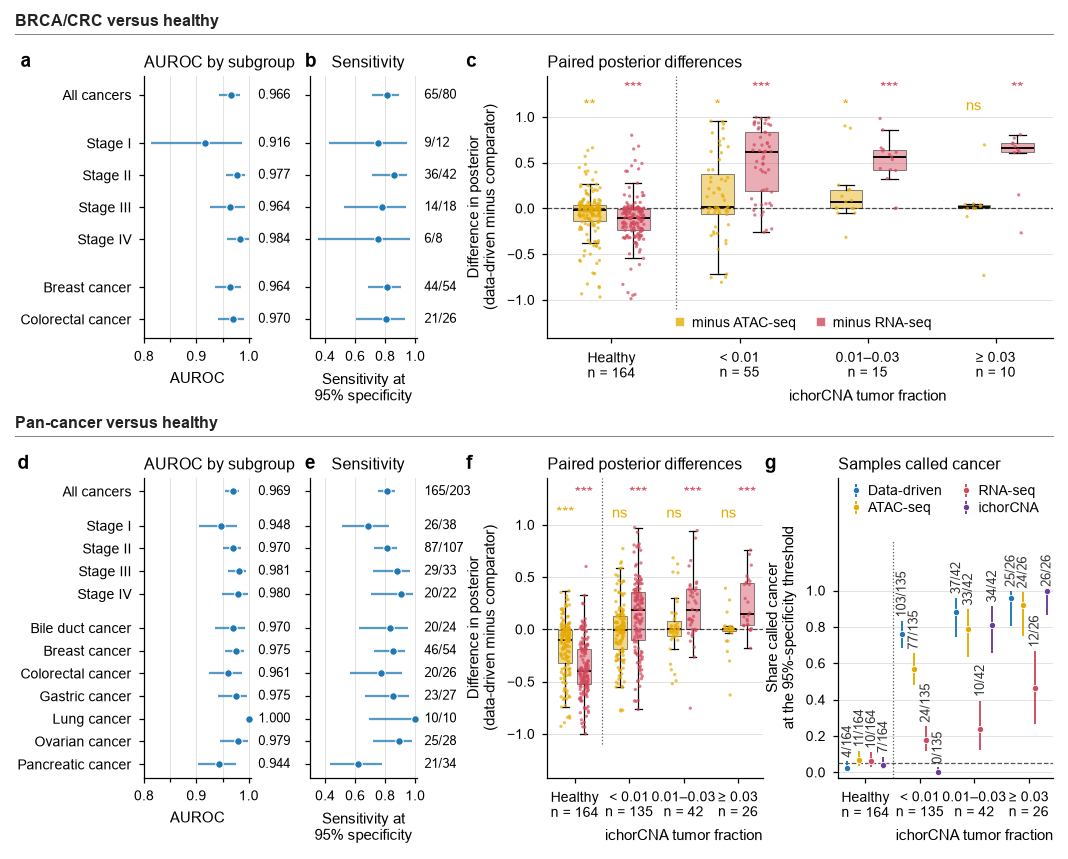

In [3]:
# Layout in inches at the printed size (180 mm wide, _figstyle): fixed positions keep the value columns, axis labels
# and titles apart. One legend per meaning: the legends of c and d serve g and h too.
W, H = fs.WIDTH, 5.55
COLS = [(x * fs.WIDTH / (180 / 25.4), w * fs.WIDTH / (180 / 25.4)) for x, w in [(0.90, 0.72), (2.02, 0.72), (3.62, 1.45), (5.58, 1.45)]]   # left edge, width of the four columns (laid out for 180 mm, scaled to fs.WIDTH)
ROWS = [(3.38, 1.75), (0.45, 2.00)]                                       # bottom edge, height of the two rows
TITLES = ("AUROC by subgroup", "Sensitivity", "Paired posterior differences", "Samples called cancer")
fig = plt.figure(figsize=(W, H))
letters = iter("abcdefg")
for r, ((y0, h), (task, title)) in enumerate(zip(ROWS, TASKS.items())):
    # BRCA/CRC: the "Samples called cancer" panel is Figure 3b, so c takes both right columns
    cols = COLS if r == 1 else COLS[:2] + [(COLS[2][0], COLS[3][0] + COLS[3][1] - COLS[2][0])]
    axes = [fig.add_axes([x0 / W, y0 / H, w / W, h / H]) for x0, w in cols]
    ax1, ax2, ax3 = axes[:3]
    panel_forest(ax1, task, "auroc", show_labels=True)
    panel_forest(ax2, task, "sensitivity", show_labels=False)
    panel_diffs(ax3, frames[task], legend=(r == 0))
    if r == 1:
        panel_calls(axes[3], frames[task], legend=True, groups=GROUPS)   # no 'All cancers' column here: too narrow
    for ax, text in zip(axes, TITLES):
        fs.panel(ax, next(letters), text)
    ax2.set_title(TITLES[1], loc="left", x=0.2)   # b has no tick labels: keep its title clear of the letter
    # task of the row, above its panel titles
    fig.text(0.03 / W, (y0 + h + 0.31) / H, title, fontsize=fs.FONT + 0.5, fontweight="bold", ha="left", va="bottom",
             color="#222222")
    fig.add_artist(Line2D([0.03 / W, (COLS[-1][0] + COLS[-1][1]) / W], [(y0 + h + 0.28) / H] * 2,
                          color="#888888", linewidth=0.5))

fs.save(fig, out_path("figS_strata"))
plt.show()

## Numbers and checks

In [4]:
# --- the numbers behind the figure, and checks --------------------------------------------------
pd.set_option("display.width", 220)

print("Columns 1 and 2 (figS10_by_stage_and_type.csv):")
show = strata_tab.assign(
    task=strata_tab["task"].map({v: TASKS[k] for k, v in S10_TASK.items()}),
    auroc_ci=strata_tab.apply(lambda r: f"{r['auroc']:.3f} [{r['auroc_lo']:.3f}, {r['auroc_hi']:.3f}]", axis=1),
    sens_ci=strata_tab.apply(lambda r: f"{r['detected']}/{r['n_cancer']} = {r['sensitivity']:.2f} [{r['sens_lo']:.2f}, {r['sens_hi']:.2f}]", axis=1))
print(show[["task", "stratum", "n_cancer", "auroc_ci", "sens_ci"]].to_string(index=False))

# the table must describe the same held-out predictions as columns 3 and 4: recompute its point values
for task in TASKS:
    df = frames[task]
    h = df[df["y_true"] == 0]
    tab = strata_tab[strata_tab["task"] == S10_TASK[task]].set_index("stratum")
    masks = {"All cancers": df["y_true"] == 1}
    masks |= {f"Stage {s}": (df["y_true"] == 1) & (df["stage"] == s) for s in STAGES}
    masks |= {d.replace(" naive nsclc", " (NSCLC)"): (df["y_true"] == 1) & (df["disease"] == d)
              for d in sorted(df.loc[df["y_true"] == 1, "disease"].unique())}
    assert set(masks) == set(tab.index), (task, set(masks) ^ set(tab.index))
    for name, mask in masks.items():
        c = df[mask]
        a = auc_from_scores(c["rank_data_driven"].to_numpy(), h["rank_data_driven"].to_numpy())
        k = int(c["call_data_driven"].sum())
        assert len(c) == tab.loc[name, "n_cancer"] and len(h) == tab.loc[name, "n_healthy"], (task, name)
        assert np.isclose(a, tab.loc[name, "auroc"]) and k == tab.loc[name, "detected"], (task, name, a, k)
    unstaged = df[(df["y_true"] == 1) & ~df["stage"].isin(STAGES)]
    print(f"{TASKS[task]}: table reproduced from the held-out predictions ({len(masks)} rows); "
          f"cancers outside stages I-IV (in no stage row): {len(unstaged)} {sorted(unstaged['stage'])}")

print("\nColumns 3 and 4:")
calls = []
for task, title in TASKS.items():
    df = frames[task]
    for grp in GROUPS:
        d = df[df["group"] == grp]
        for m in METHODS:
            k, n = int(d[f"call_{m}"].sum()), len(d)
            lo, hi = clopper_pearson(k, n)
            calls.append({"task": title, "group": grp, "method": LAB[m], "called": k, "n": n, "share": k / n, "lo": lo, "hi": hi})
    t = paired_tests(df).assign(task=title, comparator=lambda x: x["comparator"].map(LAB))
    print(f"\n{title}: paired posterior differences, data-driven minus comparator (one-sided Wilcoxon signed-rank)")
    print(t[["comparator", "group", "n", "median_difference", "alternative", "p", "mark"]].to_string(index=False, float_format=lambda x: f"{x:.3g}"))
calls = pd.DataFrame(calls)
calls["called/total"] = calls["called"].astype(str) + "/" + calls["n"].astype(str)
print("\nCalled cancer at the 95%-specificity threshold of each outer fold's training samples (called/total):")
print(calls.pivot(index=["task", "group"], columns="method", values="called/total")
      .reindex(index=[(t, g) for t in TASKS.values() for g in GROUPS], columns=[LAB[m] for m in METHODS]).to_string())


def n_called(task, grp, m):
    r = calls[(calls["task"] == TASKS[task]) & (calls["group"] == grp) & (calls["method"] == LAB[m])].iloc[0]
    return int(r["called"]), int(r["n"])


def stratum(task, name):
    return strata_tab[(strata_tab["task"] == S10_TASK[task]) & (strata_tab["stratum"] == name)].iloc[0]


# --- expected values ---------------------------------------------------------------------------
r = stratum("brca_crc", "All cancers"); assert (round(r["auroc"], 3), r["detected"], r["n_cancer"]) == (0.966, 65, 80), r
r = stratum("pancan", "All cancers"); assert (round(r["auroc"], 3), r["detected"], r["n_cancer"]) == (0.969, 165, 203), r
r = stratum("pancan", "Stage I"); assert (round(r["auroc"], 3), r["detected"], r["n_cancer"]) == (0.948, 26, 38), r
r = stratum("pancan", "Pancreatic cancer"); assert (round(r["auroc"], 3), r["n_cancer"]) == (0.944, 34), r
assert [n_called("pancan", "TF < 0.01", m) for m in METHODS] == [(103, 135), (77, 135), (24, 135), (0, 135)]
print("\nchecks passed: BRCA/CRC all cancers 0.966, 65/80; pan-cancer all cancers 0.969, 165/203; "
      "pan-cancer stage I 0.948, 26/38; pancreatic 0.944 (n = 34); pan-cancer TF < 0.01: 135 cancers, "
      "detected 103 / 77 / 24 / 0 (data-driven / ATAC-seq / RNA-seq / ichorCNA)")
print("BRCA/CRC, TF < 0.01: " + ", ".join(f"{LAB[m]} {n_called('brca_crc', 'TF < 0.01', m)[0]}/{n_called('brca_crc', 'TF < 0.01', m)[1]}" for m in METHODS))
print(f"saved {out_path('figS_strata.png')} and .pdf")

Columns 1 and 2 (figS10_by_stage_and_type.csv):
                     task             stratum  n_cancer             auroc_ci                     sens_ci
  BRCA/CRC versus healthy         All cancers        80 0.966 [0.943, 0.984]   65/80 = 0.81 [0.71, 0.89]
  BRCA/CRC versus healthy             Stage I        12 0.916 [0.814, 0.988]    9/12 = 0.75 [0.43, 0.95]
  BRCA/CRC versus healthy            Stage II        42 0.977 [0.958, 0.992]   36/42 = 0.86 [0.71, 0.95]
  BRCA/CRC versus healthy           Stage III        18 0.964 [0.926, 0.993]   14/18 = 0.78 [0.52, 0.94]
  BRCA/CRC versus healthy            Stage IV         8 0.984 [0.958, 1.000]     6/8 = 0.75 [0.35, 0.97]
  BRCA/CRC versus healthy       Breast cancer        54 0.964 [0.936, 0.986]   44/54 = 0.81 [0.69, 0.91]
  BRCA/CRC versus healthy   Colorectal cancer        26 0.970 [0.942, 0.991]   21/26 = 0.81 [0.61, 0.93]
Pan-cancer versus healthy         All cancers       203 0.969 [0.954, 0.982] 165/203 = 0.81 [0.75, 0.86]
Pan-can